# Salary comparison: NoFluffJobs vs TechCompenso

Median salary for Python-related job postings in each market.

## 1. Imports

In [119]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

## 2. Connect to the database

In [120]:
conn = sqlite3.connect("job_postings.db")

## 3. NoFluffJobs: Python-related postings

In [121]:
nf = pd.read_sql("SELECT * FROM nofluff WHERE (title LIKE '%python%' OR category LIKE '%python%' OR technology LIKE '%python%') AND `salary.from` > 0 AND `salary.to` > 0", conn)
nf_py = nf.copy()
nf_py["median_salary"] = (nf_py["salary.from"] + nf_py["salary.to"]) / 2 * 12  # monthly -> yearly
print("NoFluff python postings:", len(nf_py))
print("Median salary:", nf_py["median_salary"].median())

NoFluff python postings: 59
Median salary: 67032.0


## 4. TechCompenso: Python-related postings

In [122]:
tc = pd.read_sql("SELECT * FROM techcompenso WHERE (title LIKE '%python%' OR tags LIKE '%python%') AND salary_min > 0 AND salary_max > 0", conn)
tc_py = tc.copy()
tc_py["median_salary"] = (tc_py["salary_min"] + tc_py["salary_max"]) / 2
print("TechCompenso python postings:", len(tc_py))
print("Median salary:", tc_py["median_salary"].median())

TechCompenso python postings: 4
Median salary: 60000.0


## 5. Compare

In [123]:
comparison = pd.DataFrame({
    "source": ["NoFluffJobs", "TechCompenso"],
    "python_postings": [len(nf_py), len(tc_py)],
    "median_salary": [nf_py["median_salary"].median(), tc_py["median_salary"].median()],
})
comparison

,source,python_postings,median_salary
0,NoFluffJobs,59,67032.0
1,TechCompenso,4,60000.0


## 6. Close connection

records: 63


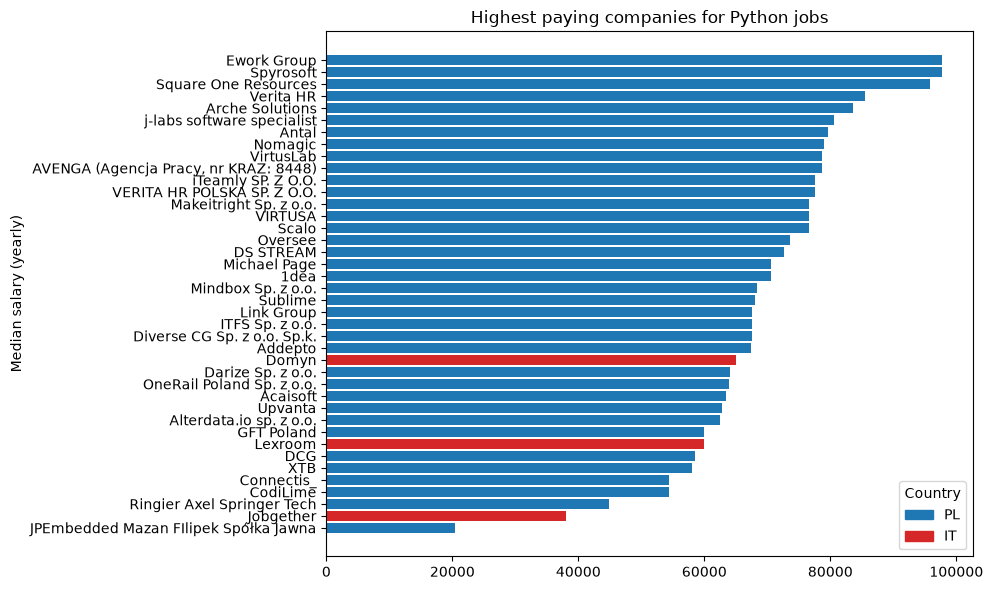

In [124]:
import matplotlib.pyplot as plt

# Top paying companies for Python jobs (combined), with country
nf_top = nf_py[["name", "median_salary"]].copy()
nf_top["company"] = nf_top["name"]
nf_top["country"] = "PL"  # NoFluffJobs postings are mostly Poland
tc_top = tc_py[["company", "median_salary"]].copy()
tc_top["country"] = "IT"  # TechCompenso is Italy
all_py = pd.concat([nf_top[["company", "median_salary", "country"]], tc_top[["company", "median_salary", "country"]]], ignore_index=True)
top = all_py.sort_values("median_salary", ascending=False)
print("records:", len(top))

colors = {"PL": "#1f77b4", "IT": "#d62728"}
bar_colors = [colors.get(c, "gray") for c in top["country"]]

plt.figure(figsize=(10, 6))
plt.barh(top["company"], top["median_salary"], color=bar_colors)
plt.title("Highest paying companies for Python jobs")
plt.ylabel("Median salary (yearly)")
plt.yticks()
# legend
from matplotlib.patches import Patch
handles = [Patch(color=colors[k], label=k) for k in colors]
plt.legend(handles=handles, title="Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [125]:
conn.close()

In [126]:
top

,company,median_salary,country
41,Ework Group,97776.0,PL
57,Spyrosoft,97776.0,PL
32,Square One Resources,95760.0,PL
46,Verita HR,85554.0,PL
7,Arche Solutions,83664.0,PL
...,...,...,...
0,Addepto,43428.0,PL
3,Addepto,43428.0,PL
62,Jobgether,38000.0,IT
9,JPEmbedded Mazan FIlipek Spółka Jawna,20406.0,PL
